# Реальные данные: параметрическая регрессия бактериального роста

Проверяем существующие `ModelSelector` и `MultiExperimentRegressor` на опубликованных
измерениях ST14028. Это вычислительная оценка предсказаний, а не проверка биологического
механизма или статистической значимости действия C8-HSL.

**Источник:** Ghosh A., Fernandes S., *Dissecting the Phenotypic Complexity of Biofilm
Development and Quorum Sensing in Salmonella enterica Serovars*, данные Figure 2,
[Zenodo, v5, 16 сентября 2026](https://zenodo.org/records/22798201),
[DOI 10.5281/zenodo.22798201](https://doi.org/10.5281/zenodo.22798201), CC-BY-4.0.
Используется именно `Figure_2_multi_species_three_concentrations_linked (2).xlsx`.
Авторские AUC, lag time и другие производные показатели не используются в регрессии.

**Запуск:** из корня проекта `uv sync --extra notebook --extra dev`, затем
`uv run jupyter lab examples/real_bacterial_growth.ipynb` и **Restart Kernel and Run All**.
CPU, seed=42. Excel уже сохранён в `data/external`; повторный запуск работает без сети.
Если файл отсутствует, загрузчик скачает его по фиксированному URL. При недоступности
сети нужно вручную сохранить файл туда с исходным именем. SHA-256 проверяется до чтения;
при несовпадении анализ останавливается, синтетической замены нет.
Чтение сохранённых значений OOXML выполняется стандартной библиотекой Python;
Excel и дополнительный движок `openpyxl` не требуются.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "examples"))
os.environ["MPLCONFIGDIR"] = str(ROOT / ".mplconfig")

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from bacterial_growth_support import (  # noqa: E402
    FIT_OPTIONS,
    OUTPUT,
    SEED,
    choose_family,
    individual_fits,
    make_split,
    plot_eda,
    plot_holdout,
    plot_individual,
    prepare_data,
    run_comparison,
    save_figure,
)
from IPython.display import Markdown, display  # noqa: E402

from parametric_regression import fit_family  # noqa: E402
from parametric_regression.multi_experiment.visualization import plot_parameter_dependency  # noqa: E402

np.random.seed(SEED)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

## 1. Аудит исходного файла и подготовка таблицы

Описание Zenodo сообщает об измерениях OD570 при 37 °C и 150 rpm, трёх биологических
повторах, усреднении технических повторов, времени 0–11 ч и контролях растворителя.
[Источник сведений о протоколе](https://zenodo.org/records/22798201).

**В выбранном файле фактически другое представление:** восемь листов; `Raw Data`
содержит 1260 наблюдений, семь кодов штаммов, 84 кривые и 15 точек 0–14 ч.
`Analysis Guide` прямо называет `Rep1–Rep3` биологическими повторами.
Есть один тип контроля `No Treatment`, отдельные blanks и технические лунки не представлены.
Все начальные OD равны 0, тогда как описание записи указывает начальную
blank-corrected OD=0,05. **Мы не добавляем 0,05, не вычитаем фон и не обрезаем время.**
Состояние фоновой коррекции в этом файле не установлено; это существенное ограничение
происхождения и интерпретации данных, несмотря на совпадение контрольной суммы с Zenodo.

Выбор **ST14028** сделан до моделирования: это явно указанный в описании штамм Salmonella
с полным дизайном (12 кривых, 180 точек), без пропусков и дубликатов.
Полнота проверяется и у остальных штаммов, сравнение ошибок моделей в выборе не участвует.
Сохраняем исходные названия условий, строки Excel, контрольный статус и метки повторов.
`experiment_id` остаётся пустым: идентификаторов запусков или дат в файле нет.
`replicate_block` — консервативная группировка одинаковых меток, не доказанная связь запусков.

In [2]:
data, sheet_audit, strain_quality = prepare_data()
display(sheet_audit, strain_quality, data.head())
display(
    data.groupby(["source_condition", "replicate_id"]).agg(
        n=("od570", "size"),
        first_h=("time_h", "min"),
        last_h=("time_h", "max"),
        minimum_od=("od570", "min"),
        maximum_od=("od570", "max"),
    )
)
print("Missing numeric values:", data[["time_h", "od570", "concentration_mM"]].isna().sum().sum())
print("Duplicated curve/time keys:", data.duplicated(["curve_id", "time_h"]).sum())
print("All initial OD570:", data.loc[data.time_h.eq(0), "od570"].unique())
print("Saved CSVs: data/processed/bacterial_growth*.csv")

,sheet,rows_including_header,columns,first_row
0,Raw Data,1261,5,"['Strain', 'Condition', 'Time (hrs)', 'Replica..."
1,Analysis Guide,28,2,"['Multi-species C8-HSL dose-response ', None]"
2,Interval Calcs,1261,11,"['Strain', 'Condition', 'Time (h)', 'Replicate..."
3,Replicate Metrics,85,10,"['Strain', 'Condition', 'Biological replicate'..."
4,Descriptive Stats,29,14,"['Strain', 'Condition', 'n', 'Mean AUC', 'SD A..."
5,Welch and Holm,22,22,"['Strain', 'Concentration', 'n treated', 'n co..."
6,Curve Summary,421,8,"['Strain', 'Condition', 'Time (h)', 'Mean OD57..."
7,Results Summary,24,9,"['Figure 2 dose-response statistical results',..."


,curves,rows,min_time,max_time,minimum_od,negative_od
strain,,,,,,
ECOLI,12,180,0.0,14.0,0.0,0
PA,12,180,0.0,14.0,0.0,0
SE,12,180,0.0,14.0,0.0,0
ST14028,12,180,0.0,14.0,0.0,0
STTA1537,12,180,0.0,14.0,0.0,0
STWT,12,180,0.0,14.0,0.0,0
SV,12,180,0.0,14.0,0.0,0


,strain,source_condition,time_h,replicate_id,od570,concentration_mM,curve_id,replicate_block,experiment_id,is_control,source_sheet,source_excel_row,background_correction
0,ST14028,No Treatment,0.0,Rep1,0.00,0.0,ST14028|No Treatment|Rep1,ST14028|Rep1,<NA>,True,Raw Data,542,not specified in this workbook
1,ST14028,No Treatment,1.0,Rep1,0.03,0.0,ST14028|No Treatment|Rep1,ST14028|Rep1,<NA>,True,Raw Data,543,not specified in this workbook
2,ST14028,No Treatment,2.0,Rep1,0.06,0.0,ST14028|No Treatment|Rep1,ST14028|Rep1,<NA>,True,Raw Data,544,not specified in this workbook
3,ST14028,No Treatment,3.0,Rep1,0.10,0.0,ST14028|No Treatment|Rep1,ST14028|Rep1,<NA>,True,Raw Data,545,not specified in this workbook
4,ST14028,No Treatment,4.0,Rep1,0.16,0.0,ST14028|No Treatment|Rep1,ST14028|Rep1,<NA>,True,Raw Data,546,not specified in this workbook


n  first_h  last_h  minimum_od  maximum_od
source_condition replicate_id                                             
C8-HSL 0.05 mM   Rep1          15      0.0    14.0         0.0       0.999
                 Rep2          15      0.0    14.0         0.0       0.995
                 Rep3          15      0.0    14.0         0.0       1.005
C8-HSL 0.2 mM    Rep1          15      0.0    14.0         0.0       1.020
                 Rep2          15      0.0    14.0         0.0       1.010
                 Rep3          15      0.0    14.0         0.0       1.037
C8-HSL 1.0 mM    Rep1          15      0.0    14.0         0.0       1.008
                 Rep2          15      0.0    14.0         0.0       1.001
                 Rep3          15      0.0    14.0         0.0       1.015
No Treatment     Rep1          15      0.0    14.0         0.0       0.990
                 Rep2          15      0.0    14.0         0.0       0.988
                 Rep3          15      0.0    14.0         0.0       0.995

Missing numeric values: 0
Duplicated curve/time keys: 0
All initial OD570: [0.]
Saved CSVs: data/processed/bacterial_growth*.csv


## 2. Описательные графики

Показываем каждый биологический повтор, среднее и выборочное SD, затем все конечные
значения. Полоса SD описывает разброс трёх наблюдаемых кривых; это не доверительный
интервал и не критерий значимости. Небольшой разброс конечной OD не гарантирует
устойчивости коэффициентов нелинейной модели.

,mean,std,min,max
source_condition,,,,
C8-HSL 0.05 mM,0.993333,0.006028,0.987,0.999
C8-HSL 0.2 mM,1.021667,0.014572,1.008,1.037
C8-HSL 1.0 mM,1.005667,0.004933,1.000,1.009
No Treatment,0.981333,0.013317,0.966,0.990


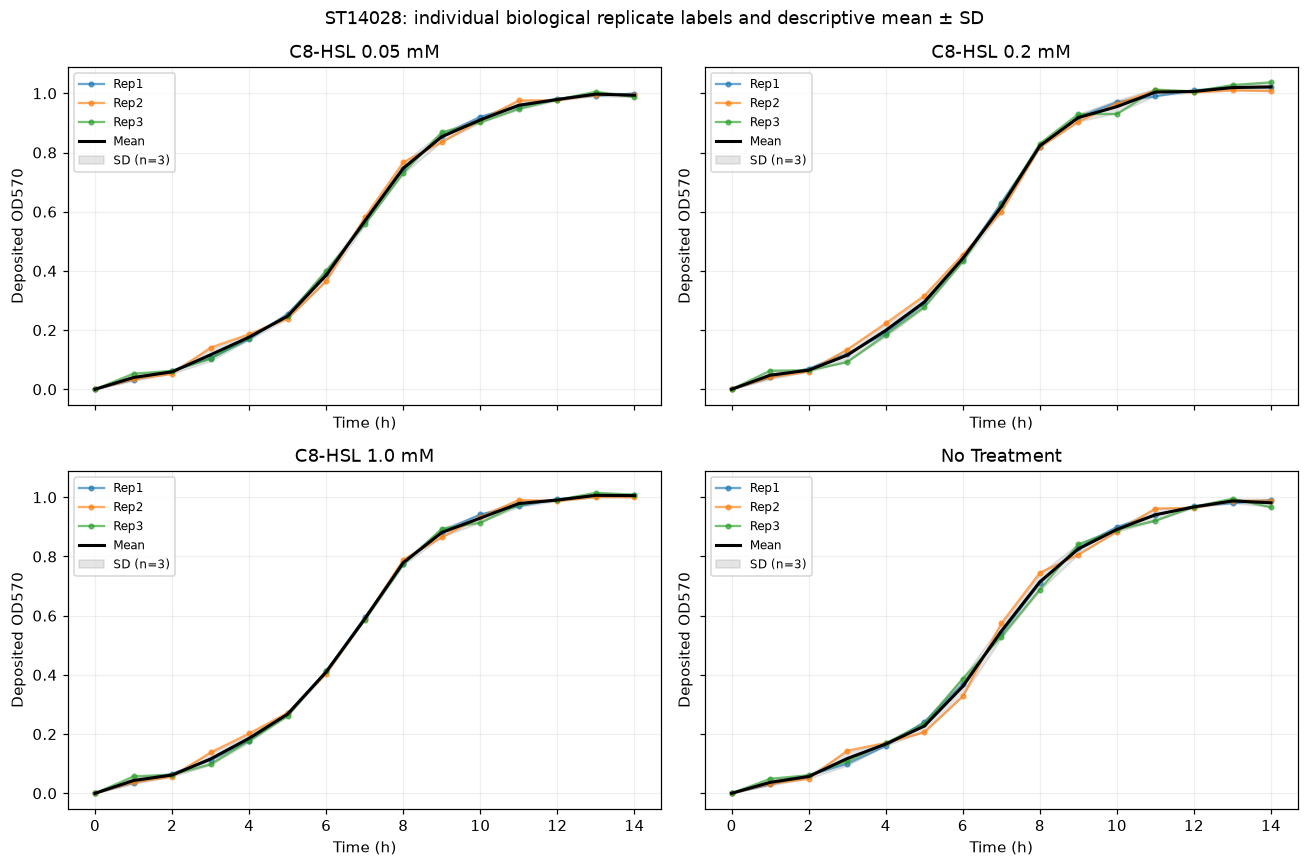

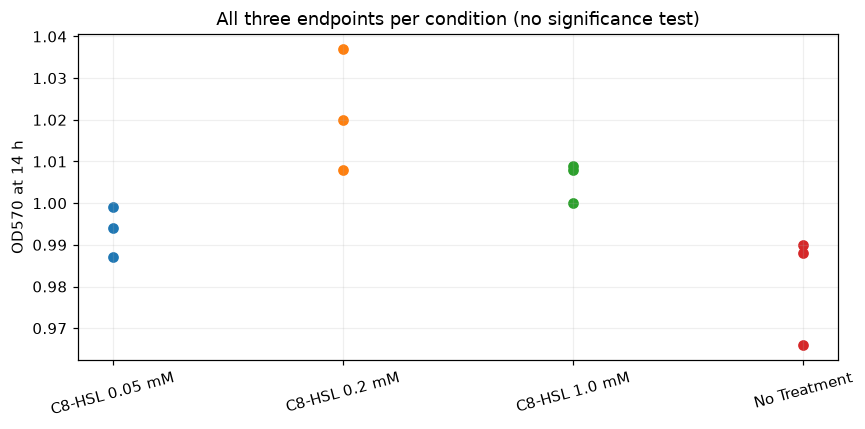

In [3]:
endpoints = plot_eda(data)
display(endpoints)
plt.show()

## 3. Протокол, зафиксированный до выбора моделей

**A — продолжение отдельной кривой:** у каждой из 12 кривых обучаем семь кандидатов на
0–11 ч, сравниваем на 12–14 ч. Полиномы 1/2/3, экспонента, логистика, Гомпертц,
рациональное насыщение. Бюджет 2000 вычислений на старт, до 12 детерминированных стартов.
Выбор `ModelSelector` по validation RMSE с допуском 1% в пользу простоты.
Ошибки победителей на этих же точках — **ошибки выбора**, а не независимый final test.
Короткое плато делает R² чувствительным к очень малой дисперсии; основной критерий RMSE.

**B — новая концентрация:** все три кривые 0,2 мМ полностью исключаются из выбора семейства,
подбора коэффициентов, масштабирования и выбора сложности.
`No Treatment` не включается: соответствие vehicle-matched контролю не подтверждено.
Доступные для разработки уровни — 0,05 и 1,0 мМ. `Rep1/Rep2` на этих уровнях — fit-train
(4 кривые, 60 точек), весь `Rep3` на них — inner-validation (2 кривые, 30 точек).
Test — 3 кривые, 45 точек 0,2 мМ. Разбиение сохраняется построчно в CSV.

Общее семейство выбираем **только** по хронологическим ошибкам четырёх fit-train кривых:
среднее RMSE, полное покрытие и полный ранг нормированного якобиана, condition < 1e8;
при разнице до 1% предпочитаем меньше параметров. Затем библиотека заново подбирает
его коэффициенты по всем 15 точкам каждой fit-train кривой. Constant/Linear выбираются
на inner-validation в пространстве OD, не на тесте. Квадратичная зависимость от C
не идентифицируется по двум уровням и не предлагается.

API библиотеки сохраняет validation отдельно и **не переобучает на train+validation**.
Поэтому все baseline также обучаются только на тех же 60 точках.
Для задачи новой концентрации повторные метки пересекают outer-разделение:
`analysis_group = partition|replicate_block` обозначает расчётный блок, а не новый
независимый эксперимент. Сценарий оценивает новую концентрацию в этом наборе повторов,
не перенос на новую биологическую реализацию.

Диагностический A рассчитывается для всех кривых, но его результаты по test-концентрации
не передаются в правило выбора B. Ни одна формула B не использует начальный OD теста.

In [4]:
individual, candidates = individual_fits(data)
family_summary = candidates.groupby("family").agg(
    successful=("success", "sum"),
    attempted=("success", "size"),
    success_fraction=("success", "mean"),
    mean_mae=("validation_mae", "mean"),
    mean_rmse=("validation_rmse", "mean"),
    mean_r2=("validation_r2", "mean"),
)
family_summary.to_csv(OUTPUT / "individual_family_summary.csv")
display(
    family_summary,
    candidates.loc[
        candidates.selected,
        [
            "curve_id",
            "family",
            "validation_mae",
            "validation_rmse",
            "validation_r2",
            "coefficients",
        ],
    ],
)
failures = candidates.loc[~candidates.success, ["curve_id", "family", "message"]]
display(failures)
print(f"Optimization failures: {len(failures)}/{len(candidates)}")
display(
    candidates.loc[
        candidates.jacobian_condition >= 1e8, ["curve_id", "family", "jacobian_condition"]
    ]
)

,successful,attempted,success_fraction,mean_mae,mean_rmse,mean_r2
family,,,,,,
exponential,12,12,1.0,0.392789,0.416096,-4344.911528
gompertz,12,12,1.0,0.040152,0.041072,-24.469645
logistic,12,12,1.0,0.016369,0.017003,-36.934730
polynomial_1,12,12,1.0,0.190705,0.205730,-1327.207953
polynomial_2,12,12,1.0,0.395764,0.417378,-4437.512973
polynomial_3,12,12,1.0,0.067170,0.086292,-249.134513
rational_saturation,12,12,1.0,0.190705,0.205730,-1327.207825


,curve_id,family,validation_mae,validation_rmse,validation_r2,coefficients
4,ST14028|C8-HSL 0.05 mM|Rep1,logistic,0.008497,0.008569,-0.508769,"{""c"": 0.011857888098310721, ""L"": 1.00296353177..."
11,ST14028|C8-HSL 0.05 mM|Rep2,logistic,0.018233,0.018538,-3.508777,"{""c"": 0.016461970263004222, ""L"": 1.00665999602..."
18,ST14028|C8-HSL 0.05 mM|Rep3,logistic,0.008334,0.010181,0.123232,"{""c"": 0.01945194576828546, ""L"": 0.982261007184..."
25,ST14028|C8-HSL 0.2 mM|Rep1,logistic,0.014814,0.014938,-9.041450,"{""c"": 0.018013551053157006, ""L"": 1.02375839344..."
33,ST14028|C8-HSL 0.2 mM|Rep2,gompertz,0.003459,0.003859,-0.718590,"{""c"": 1.0044782820456555, ""L"": -1.047083311972..."
39,ST14028|C8-HSL 0.2 mM|Rep3,logistic,0.008462,0.008839,0.539191,"{""c"": 0.026800099223158947, ""L"": 1.00256568221..."
46,ST14028|C8-HSL 1.0 mM|Rep1,logistic,0.010568,0.010615,-2.250493,"{""c"": 0.014406950228403862, ""L"": 1.01105389259..."
54,ST14028|C8-HSL 1.0 mM|Rep2,gompertz,0.020460,0.021420,-10.282577,"{""c"": 0.9755649974754779, ""L"": -1.001214887690..."
60,ST14028|C8-HSL 1.0 mM|Rep3,logistic,0.005012,0.006781,0.557818,"{""c"": 0.022225483263019343, ""L"": 0.99066717971..."
67,ST14028|No Treatment|Rep1,logistic,0.007441,0.007663,0.119072,"{""c"": 0.009492388240651335, ""L"": 0.99619627366..."


,curve_id,family,message


Optimization failures: 0/84


,curve_id,family,jacobian_condition
6,ST14028|C8-HSL 0.05 mM|Rep1,rational_saturation,1.689233e+08
13,ST14028|C8-HSL 0.05 mM|Rep2,rational_saturation,1.760259e+08
20,ST14028|C8-HSL 0.05 mM|Rep3,rational_saturation,1.825648e+08
27,ST14028|C8-HSL 0.2 mM|Rep1,rational_saturation,3.837242e+08
34,ST14028|C8-HSL 0.2 mM|Rep2,rational_saturation,1.549476e+08
41,ST14028|C8-HSL 0.2 mM|Rep3,rational_saturation,4.170000e+08
48,ST14028|C8-HSL 1.0 mM|Rep1,rational_saturation,2.286540e+08
55,ST14028|C8-HSL 1.0 mM|Rep2,rational_saturation,2.075428e+08
62,ST14028|C8-HSL 1.0 mM|Rep3,rational_saturation,2.443718e+08
69,ST14028|No Treatment|Rep1,rational_saturation,2.446888e+08


,family,index,n_parameters,complete,stable,mean_validation_rmse
0,polynomial_1,0,2,True,True,0.207972
1,polynomial_2,1,3,True,True,0.419673
2,polynomial_3,2,4,True,True,0.071559
3,exponential,3,3,True,True,0.418760
4,logistic,4,4,True,True,0.018940
5,gompertz,5,4,True,True,0.035603
6,rational_saturation,6,3,True,False,inf


Selected on fit-train only: logistic


,curves,rows
partition,,
test,3,45
train,4,60
validation,2,30


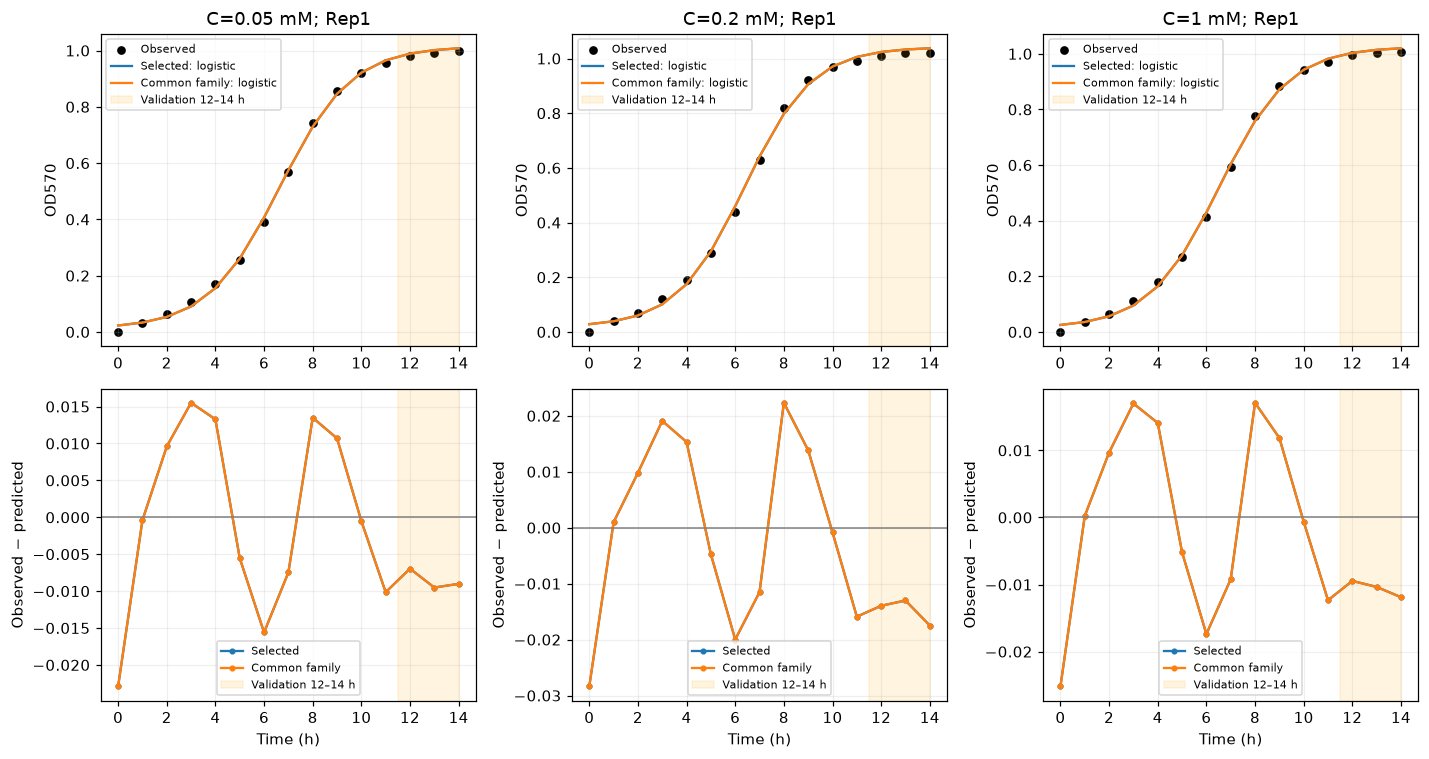

In [5]:
split = make_split(data)
train_ids = set(split.loc[split.partition.eq("train"), "curve_id"])
common_family, common_family_scores = choose_family(individual, train_ids)
display(common_family_scores)
print("Selected on fit-train only:", common_family.name)
display(split.groupby("partition").agg(curves=("curve_id", "nunique"), rows=("time_h", "size")))
plot_individual(data, individual, common_family.name)
plt.show()

## 4. Общая модель и baseline на одинаковом разбиении

`MultiExperimentRegressor` проверяет все сочетания Constant/Linear (16 для четырёх
логистических параметров). Логистика имеет вид $c+L/(1+\exp[-k(t-x_0)])$.
Используются штатные ограничения и преобразования семейства.

**Direct Polynomial:** sklearn `StandardScaler`, `PolynomialFeatures` и `LinearRegression`;
общая степень 1, 2 или 3 выбирается на inner-validation, допуск 1% в пользу меньшей степени.
Сохраняем только мономы с показателем C ≤ 1: при двух fit-train уровнях C² и C³
не дают идентифицируемых дополнительных эффектов. Таким образом, для степени 3 базис
содержит 1, t, C, t², tC, t³, t²C (в масштабированных координатах).
Это прямой двумерный полином, без индивидуальных подгонок кривых.

**Nearest concentration:** средняя по fit-train повторам кривая ближайшего уровня C,
без использования validation/test значений. Все времена уже представлены в train.
Итоговые MAE/RMSE/R² считаются по всем 45 тестовым точкам (равная длина повторов),
а также отдельно по каждому повтору.

,approach,mae,rmse,r2
0,Direct Polynomial,0.039077,0.052798,0.982661
1,MultiExperimentRegressor,0.034021,0.041107,0.989490
2,Nearest concentration,0.034000,0.041621,0.989225


,approach,replicate_id,mae,rmse,r2
0,Direct Polynomial,Rep1,0.038021,0.052898,0.982667
1,Direct Polynomial,Rep2,0.038483,0.048777,0.984817
2,Direct Polynomial,Rep3,0.040729,0.056439,0.980597
3,MultiExperimentRegressor,Rep1,0.034177,0.039853,0.990162
4,MultiExperimentRegressor,Rep2,0.035177,0.042275,0.988595
5,MultiExperimentRegressor,Rep3,0.032710,0.041157,0.989682
6,Nearest concentration,Rep1,0.033067,0.040655,0.989762
7,Nearest concentration,Rep2,0.033600,0.041943,0.988774
8,Nearest concentration,Rep3,0.035333,0.042246,0.989128


,degree,terms,mae,rmse,r2,selected
0,1,2,0.080685,0.092688,0.943609,False
1,2,4,0.079289,0.089785,0.947086,False
2,3,6,0.030513,0.035537,0.991711,True


,candidate,models,n_coefficients,validation_score,validation_observation_rmse,validation_experiment_rmse,success,selected,message
0,0,"{'c': 'constant', 'L': 'constant', 'k': 'const...",4,0.017477,0.017477,0.017477,True,False,
1,1,"{'c': 'constant', 'L': 'constant', 'k': 'const...",5,0.016013,0.016013,0.016013,True,False,
2,2,"{'c': 'constant', 'L': 'constant', 'k': 'linea...",5,0.017408,0.017408,0.017408,True,False,
3,3,"{'c': 'constant', 'L': 'constant', 'k': 'linea...",6,0.015941,0.015941,0.015941,True,False,
4,4,"{'c': 'constant', 'L': 'linear', 'k': 'constan...",5,0.016122,0.016122,0.016122,True,False,
5,5,"{'c': 'constant', 'L': 'linear', 'k': 'constan...",6,0.015364,0.015364,0.015364,True,True,
6,6,"{'c': 'constant', 'L': 'linear', 'k': 'linear'...",6,0.016077,0.016077,0.016077,True,False,
7,7,"{'c': 'constant', 'L': 'linear', 'k': 'linear'...",7,0.015320,0.015320,0.015320,True,False,
8,8,"{'c': 'linear', 'L': 'constant', 'k': 'constan...",5,0.017594,0.017594,0.017594,True,False,
9,9,"{'c': 'linear', 'L': 'constant', 'k': 'constan...",6,0.016061,0.016061,0.016061,True,False,


MultiExperimentRegressor: True Selected auto coefficient models using experiment-aggregated validation curve RMSE.
Warnings: ()


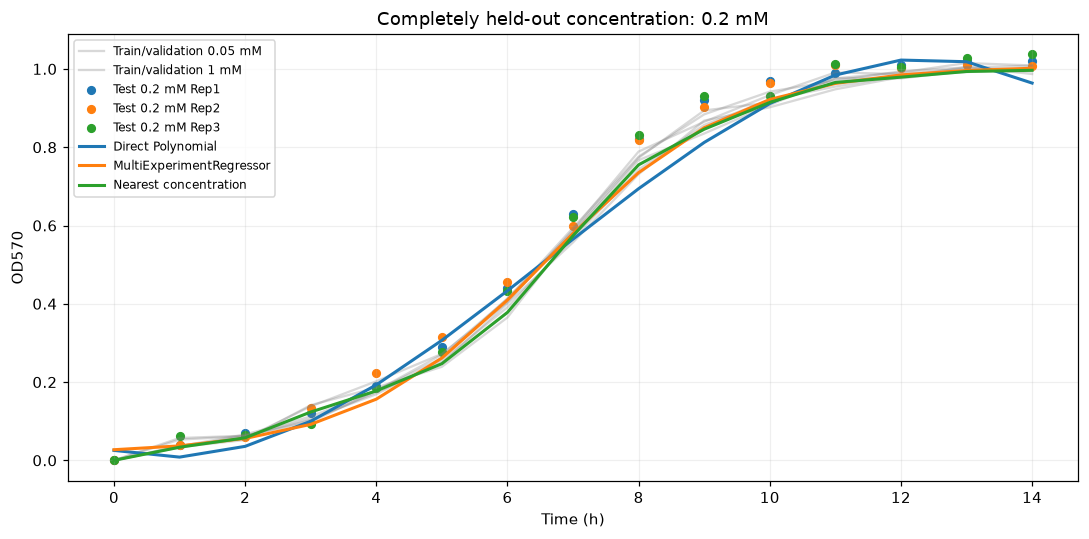

In [6]:
model, comparison, predictions, _ = run_comparison(split, individual, "new_concentration")
display(comparison)
display(pd.read_csv(OUTPUT / "new_concentration_metrics_by_replicate.csv"))
display(pd.read_csv(OUTPUT / "new_concentration_direct_selection.csv"))
display(model.candidate_scores)
print("MultiExperimentRegressor:", model.success, model.message)
print("Warnings:", model.warnings)
assert model.success, model.message
assert model.metrics["test"]["complete"]
assert predictions.groupby("approach").size().eq(45).all()
assert not model.experiment_parameters.loc[
    model.experiment_parameters.partition.ne("train"), "fit_success"
].any()
plot_holdout(split, predictions)
plt.show()

## 5. Коэффициенты, общая формула и устойчивость

На графиках — оценки по полным fit-train кривым и выбранные зависимости от C.
Вторая таблица ниже дополнительно оценивает одно фиксированное семейство на всех
шести доступных для разработки кривых (включая inner-validation), **после фиксации B**.
Это только диагностика разброса; эти дополнительные fit не меняют модель и её метрики.
Test-концентрация 0,2 мМ в эту диагностику не входит.

,trajectory_id,experiment_id,partition,n_observations,time_origin,initial_value,fit_success,used_for_parameter_models,message,condition:concentration_mM,param:c,param:L,param:k,param:x0,jacobian_rank,jacobian_condition,fit_warnings,fit_mae,fit_rmse,fit_r2
0,ST14028|C8-HSL 0.05 mM|Rep1,train|ST14028|Rep1,train,15,0.0,None,True,True,`ftol` termination condition is satisfied.,0.05,0.013870,0.992837,0.689490,6.614268,4.0,6.330377,,0.008720,0.010989,0.999204
1,ST14028|C8-HSL 0.05 mM|Rep2,train|ST14028|Rep2,train,15,0.0,None,True,True,`ftol` termination condition is satisfied.,0.05,0.021134,0.984289,0.698206,6.640827,4.0,6.210702,,0.018332,0.023319,0.996391
2,ST14028|C8-HSL 0.05 mM|Rep3,validation|ST14028|Rep3,validation,15,0.0,None,False,False,Held-out trajectory: not fitted.,0.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ST14028|C8-HSL 0.2 mM|Rep1,test|ST14028|Rep1,test,15,0.0,None,False,False,Held-out trajectory: not fitted.,0.20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ST14028|C8-HSL 0.2 mM|Rep2,test|ST14028|Rep2,test,15,0.0,None,False,False,Held-out trajectory: not fitted.,0.20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ST14028|C8-HSL 0.2 mM|Rep3,test|ST14028|Rep3,test,15,0.0,None,False,False,Held-out trajectory: not fitted.,0.20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ST14028|C8-HSL 1.0 mM|Rep1,train|ST14028|Rep1,train,15,0.0,None,True,True,`ftol` termination condition is satisfied.,1.00,0.016866,0.999029,0.709709,6.494309,4.0,6.238803,,0.009873,0.012364,0.999018
7,ST14028|C8-HSL 1.0 mM|Rep2,train|ST14028|Rep2,train,15,0.0,None,True,True,`ftol` termination condition is satisfied.,1.00,0.016994,1.000366,0.683219,6.487777,4.0,6.534757,,0.015819,0.020146,0.997347
8,ST14028|C8-HSL 1.0 mM|Rep3,validation|ST14028|Rep3,validation,15,0.0,None,False,False,Held-out trajectory: not fitted.,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**c(C)**: `(0.0172159292927)`

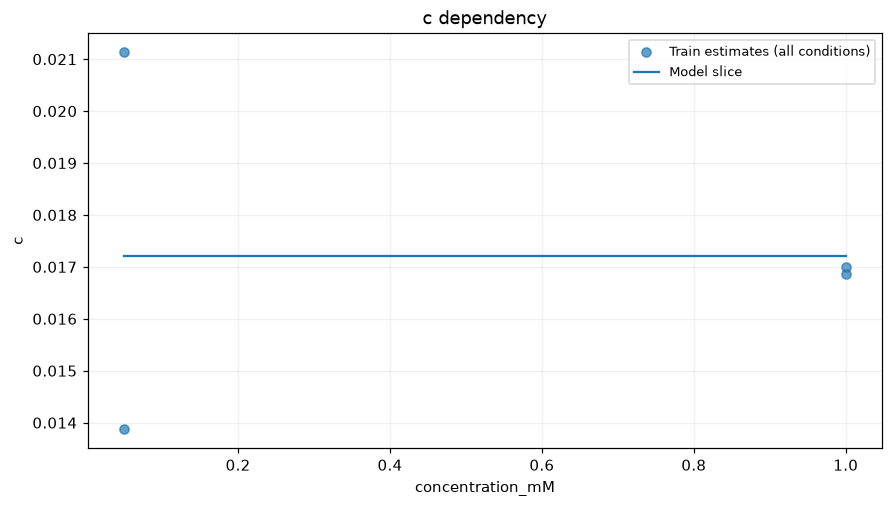

**L(C)**: `(0.994130197979) + (0.00556723663386)*((concentration_mM - (0.525))/(0.475))`

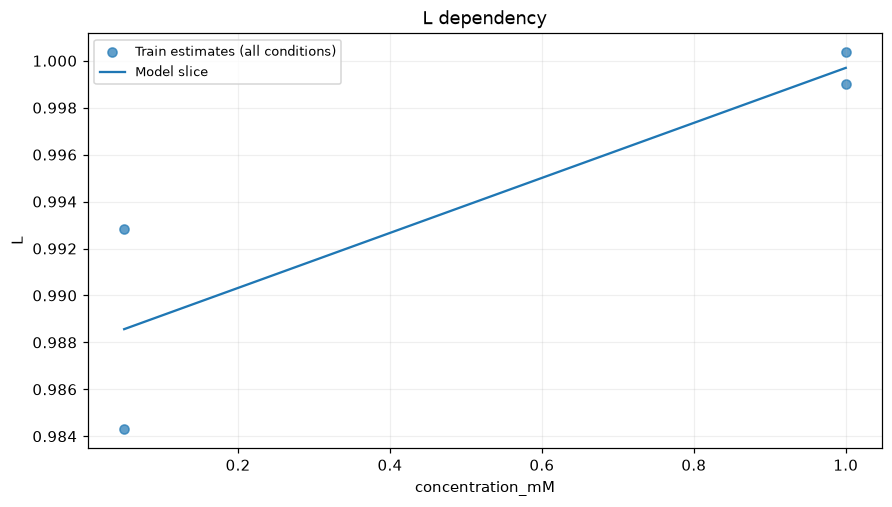

**k(C)**: `(0.695156144868)`

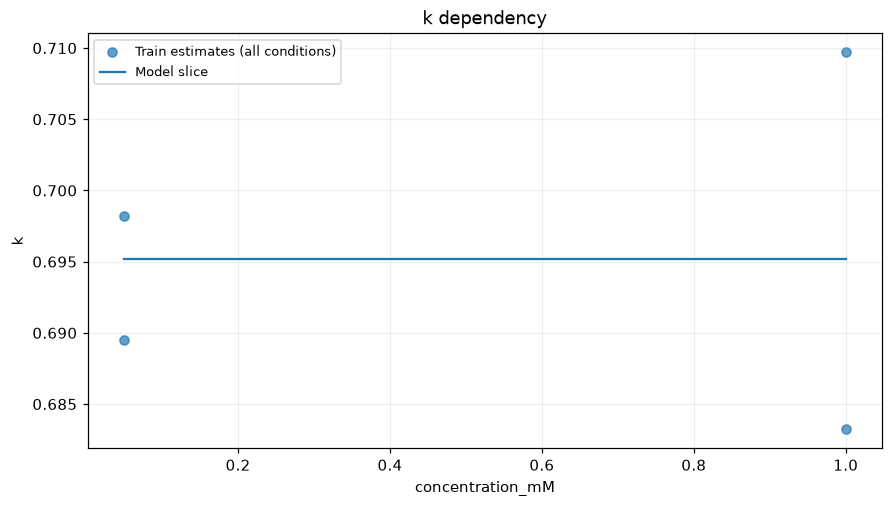

**x0(C)**: `(6.55929497011) + (-0.0682521382502)*((concentration_mM - (0.525))/(0.475))`

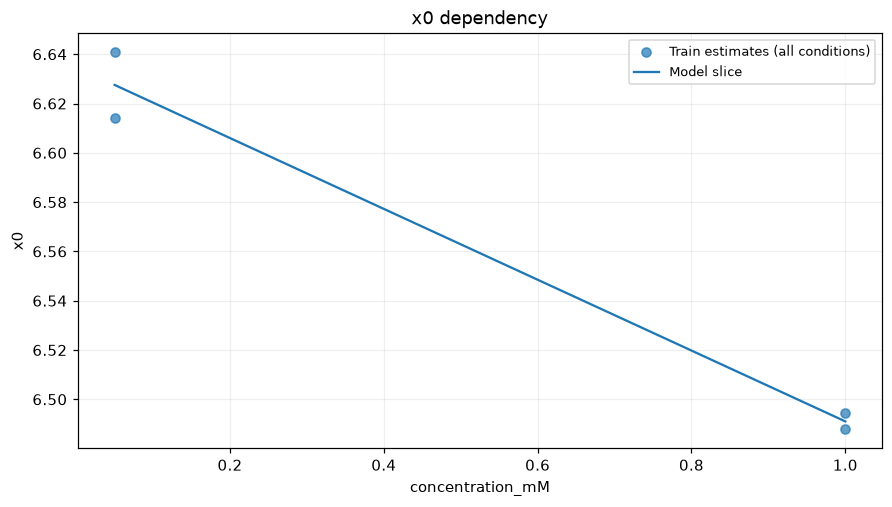

Итоговая формула библиотеки:
y(t, concentration_mM) = ((0.0172159292927)) + ((0.994130197979) + (0.00556723663386)*((concentration_mM - (0.525))/(0.475)))/(1 + exp(-((0.695156144868))*(t - ((6.55929497011) + (-0.0682521382502)*((concentration_mM - (0.525))/(0.475))))))


,curve_id,concentration_mM,replicate_id,success,jacobian_condition,message,c,L,k,x0,mae,rmse,r2
0,ST14028|C8-HSL 0.05 mM|Rep1,0.05,Rep1,True,6.330377,`ftol` termination condition is satisfied.,0.013870,0.992837,0.689490,6.614268,0.008720,0.010989,0.999204
1,ST14028|C8-HSL 0.05 mM|Rep2,0.05,Rep2,True,6.210702,`ftol` termination condition is satisfied.,0.021134,0.984289,0.698206,6.640827,0.018332,0.023319,0.996391
2,ST14028|C8-HSL 0.05 mM|Rep3,0.05,Rep3,True,6.322238,`ftol` termination condition is satisfied.,0.019163,0.984672,0.687422,6.645081,0.012102,0.014360,0.998617
3,ST14028|C8-HSL 1.0 mM|Rep1,1.00,Rep1,True,6.238803,`ftol` termination condition is satisfied.,0.016866,0.999029,0.709709,6.494309,0.009873,0.012364,0.999018
4,ST14028|C8-HSL 1.0 mM|Rep2,1.00,Rep2,True,6.534757,`ftol` termination condition is satisfied.,0.016994,1.000366,0.683219,6.487777,0.015819,0.020146,0.997347
5,ST14028|C8-HSL 1.0 mM|Rep3,1.00,Rep3,True,6.113813,`ftol` termination condition is satisfied.,0.021414,0.994285,0.717267,6.543585,0.012473,0.015279,0.998498


c                                       L            \
                      mean       std       min       max      mean       std   
concentration_mM                                                               
0.05              0.018056  0.003757  0.013870  0.021134  0.987266  0.004828   
1.00              0.018425  0.002589  0.016866  0.021414  0.997893  0.003195   

                                             k                                \
                       min       max      mean       std       min       max   
concentration_mM                                                               
0.05              0.984289  0.992837  0.691706  0.005723  0.687422  0.698206   
1.00              0.994285  1.000366  0.703398  0.017880  0.683219  0.717267   

                        x0                                
                      mean       std       min       max  
concentration_mM                                          
0.05              6.633392  0.016698  6.614268  6.645081  
1.00              6.508557  0.030511  6.487777  6.543585

In [7]:
display(model.experiment_parameters)
for parameter, formula in model.parameter_formulas.items():
    display(Markdown(f"**{parameter}(C)**: `{formula}`"))
    fig = plot_parameter_dependency(model, parameter, "concentration_mM")
    save_figure(fig, f"parameter_{parameter}")
    plt.show()
print("Итоговая формула библиотеки:")
print(model.formula)

fixed_records = []
for curve_id, curve in split.loc[split.partition.ne("test")].groupby("curve_id"):
    fitted = fit_family(common_family, curve.time_h, curve.od570, **FIT_OPTIONS)
    fixed_records.append(
        {
            "curve_id": curve_id,
            "concentration_mM": curve.concentration_mM.iloc[0],
            "replicate_id": curve.replicate_id.iloc[0],
            "success": fitted.success,
            "jacobian_condition": fitted.jacobian_condition,
            "message": fitted.message,
            **fitted.coefficients,
            **fitted.train_metrics,
        }
    )
fixed_diagnostics = pd.DataFrame(fixed_records)
fixed_diagnostics.to_csv(OUTPUT / "fixed_family_full_curve_diagnostics.csv", index=False)
coefficient_summary = fixed_diagnostics.groupby("concentration_mM")[
    list(common_family.parameter_names)
].agg(["mean", "std", "min", "max"])
coefficient_summary.to_csv(OUTPUT / "coefficient_stability.csv")
display(fixed_diagnostics, coefficient_summary)

## 6. Чувствительность к исключению метки биологического повтора

`Analysis Guide` подтверждает биологический тип повторов, но не содержит общей карты
экспериментов по концентрациям. Поэтому ниже — **условная проверка по меткам Rep**,
а не доказанная оценка независимых экспериментальных запусков. Если одинаковые Rep
означают общие запуски, мы исключаем их целиком сразу на всех трёх treated-концентрациях.

По очереди test=Rep1/Rep2/Rep3. Из двух оставшихся меток меньшая идёт в fit-train,
большая — в validation. Семейство выбирается заново только по fit-train; затем
выбираются Constant/Linear и степень baseline. API не refit на двух метках после выбора,
так что фактически fit использует **одну** метку, validation — вторую.
При трёх уровнях технически возможен quadratic, но здесь он заранее исключён:
один fit-повтор и три уровня слишком слабо обосновывают дополнительные параметры.
Результаты этого сценария не объединяем с новой концентрацией.

In [8]:
replicate_tables = []
for replicate in ("Rep1", "Rep2", "Rep3"):
    replicate_model, table, _, _ = run_comparison(
        make_split(data, replicate), individual, f"replicate_{replicate}"
    )
    table["heldout_replicate"] = replicate
    table["time_family"] = replicate_model.time_family.name
    replicate_tables.append(table)
replicate_comparison = pd.concat(replicate_tables, ignore_index=True)
replicate_comparison.to_csv(OUTPUT / "replicate_sensitivity.csv", index=False)
display(replicate_comparison)

,approach,mae,rmse,r2,heldout_replicate,time_family
0,Direct Polynomial,0.032815,0.039244,0.990158,Rep1,gompertz
1,MultiExperimentRegressor,0.015755,0.021331,0.997092,Rep1,gompertz
2,Nearest concentration,0.012689,0.015881,0.998388,Rep1,gompertz
3,Direct Polynomial,0.031071,0.038870,0.990167,Rep2,logistic
4,MultiExperimentRegressor,0.021560,0.027460,0.995093,Rep2,logistic
5,Nearest concentration,0.012689,0.015881,0.998359,Rep2,logistic
6,Direct Polynomial,0.035080,0.042273,0.988576,Rep3,logistic
7,MultiExperimentRegressor,0.019094,0.023978,0.996325,Rep3,logistic
8,Nearest concentration,0.010111,0.013219,0.998883,Rep3,logistic


## 7. Выводы и ограничения

Следующая таблица повторяет **только финальный тест новой концентрации**.
Более подробные результаты, параметры, все кандидаты, split-ID и версии пакетов
сохраняются в `artifacts/real_bacterial_growth/`; исходный и обработанный наборы — в `data/`.

In [9]:
display(
    comparison.set_index("approach").rename(
        columns={"mae": "Test MAE", "rmse": "Test RMSE", "r2": "Test R²"}
    )
)
logistic_score = family_summary.loc["logistic", "mean_rmse"]
scores = comparison.set_index("approach")
display(
    Markdown(
        f"Средняя хронологическая validation RMSE логистики: **{logistic_score:.6f}**. "
        f"На новой концентрации RMSE двухэтапной модели: "
        f"**{scores.loc['MultiExperimentRegressor', 'rmse']:.6f}**, "
        f"прямого полинома: **{scores.loc['Direct Polynomial', 'rmse']:.6f}**, "
        f"ближайшей концентрации: **{scores.loc['Nearest concentration', 'rmse']:.6f}**."
    )
)

,Test MAE,Test RMSE,Test R²
approach,,,
Direct Polynomial,0.039077,0.052798,0.982661
MultiExperimentRegressor,0.034021,0.041107,0.989490
Nearest concentration,0.034000,0.041621,0.989225


Средняя хронологическая validation RMSE логистики: **0.017003**. На новой концентрации RMSE двухэтапной модели: **0.041107**, прямого полинома: **0.052798**, ближайшей концентрации: **0.041621**.

**Насколько точно описываются отдельные кривые?** В выполненном запуске логистика выиграла
10 из 12 сравнений, Гомпертц — 2. Средняя late-validation RMSE фиксированной логистики
около 0,017 OD. Все 84 оптимизации формально успешны; рациональное насыщение имеет
condition до 4,17·10⁸ и было отвергнуто правилом устойчивости для общей модели.
Успех оптимизатора не равен идентифицируемости параметров. Отрицательные R² на коротком
плато показывают, что ошибка относительно локальной дисперсии может оставаться большой.

**Стабильны ли коэффициенты?** Численные SD и диапазоны приведены выше отдельно для
каждого уровня C. Разброс c и k между повторами сопоставим с малыми различиями по C;
поэтому выбранная модель сохраняет их константами. Амплитуда L и сдвиг x0 меняются
между уровнями, но три повтора не дают надёжной оценки неопределённости.
Коэффициенты характеризуют форму аппроксимации, а не измеренные механистические скорости.

**Есть ли зависимость от концентрации?** Выбор по validation оставил линейные L(C), x0(C)
и постоянные c, k. По двум уровням нельзя проверить кривизну или монотонность во всём
интервале. Предпочтение Linear в этой процедуре не доказывает статистически значимый эффект.

**Предсказывается ли новая концентрация?** На полностью исключённых 0,2 мМ RMSE ≈0,0411,
R²≈0,9895. Начальные измерения теста не использованы. Остатки на графике показывают
несоответствие точной формы кривой, несмотря на высокий общий R², который в значительной
мере отражает общий временной рост.

**Есть ли преимущество перед baseline?** Прямой полином хуже по MAE/RMSE в этом разбиении;
ближайшая концентрация почти равна по RMSE и чуть лучше по MAE. В проверке по меткам
нового повтора ближайшая средняя кривая лучше двухэтапной модели. Поэтому результат
не подтверждает универсального преимущества параметризации.

**Что ограничивает алгоритм и выводы?** Мало концентраций и повторов; неопределённые
cross-condition experiment-ID и обработка фона; расхождения файла с метаданными;
отсутствие интервалов неопределённости и учёта погрешности коэффициентов на втором этапе;
локальные оптимумы и обусловленность; подбор формы временной зависимости отдельно от
общей ошибки OD; отсутствие штатного refit на train+validation. Последнее здесь явно
соблюдено и у baseline. Тест относится только к выбранному штамму, диапазону времени
0–14 ч и этому файлу. Для биологических выводов нужно уточнить происхождение данных,
соответствие контролей и карту независимых запусков у авторов.